# 시각화 연습문제 — tips 데이터
동국대 AI캠퍼스 · 시각화 파트

**실습본 (직접 작성)**

- 데이터: `tips` **하나로** 진행 (식당 결제·팁, seaborn 내장 실제 데이터)
- 순서: A 기본 → B 서브플롯 → C seaborn → D 미션 → E 제출 과제

## 준비

In [1]:
# ------------------------------------------------------
# 라이브러리 · 한글 폰트 · 데이터 준비
# ------------------------------------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import platform
_os = platform.system()
if _os == 'Windows':
    plt.rc('font', family='Malgun Gothic')
elif _os == 'Darwin':
    plt.rc('font', family='AppleGothic')
else:
    plt.rc('font', family='NanumGothic')
plt.rc('axes', unicode_minus=False)

# 하나의 데이터로 진행합니다 : tips (식당 결제·팁 데이터)
tips = sns.load_dataset('tips')
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


## A. matplotlib 기본

### 문제 1. 꺾은선 — 요일별 평균 결제금액
요일별 평균 `total_bill`을 구해 **꺾은선**으로 그리세요. (marker='o', 제목·축라벨)

> 힌트: `tips.groupby('day')['total_bill'].mean()`

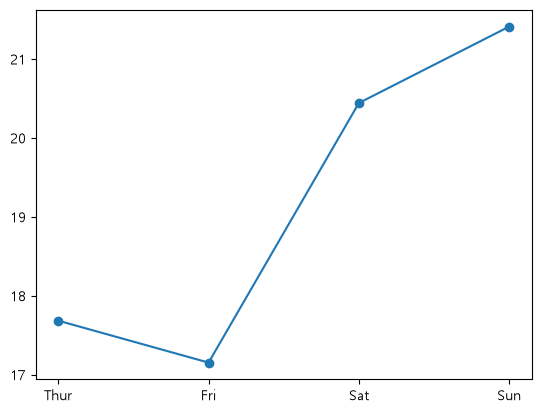

In [8]:
day_bill = tips.groupby('day')['total_bill'].mean()
day_bill
# TODO: day_bill 을 꺾은선 그래프로 그리세요

plt.plot(day_bill.index, day_bill.values, marker='o')

### 문제 2. 막대 — 요일별 평균 팁
요일별 평균 `tip`을 막대그래프로 그리세요.

<BarContainer object of 4 artists>

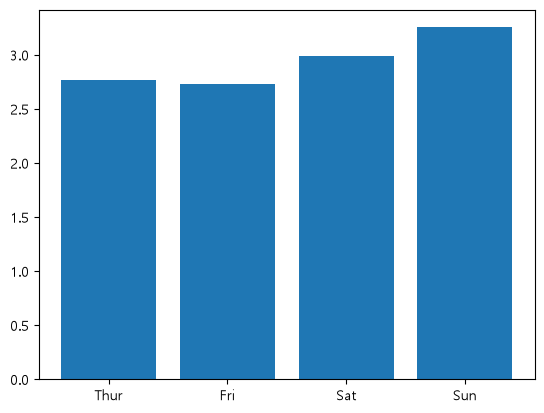

In [5]:
day_tip = tips.groupby('day')['tip'].mean()

# TODO: day_tip 을 막대그래프로 그리세요

plt.bar(day_tip.index, day_tip.values)

### 문제 3. 파이 — 요일별 방문 비율
요일별 방문 횟수의 비율을 파이그래프로 그리세요. (autopct 사용)

> 힌트: `tips['day'].value_counts()`

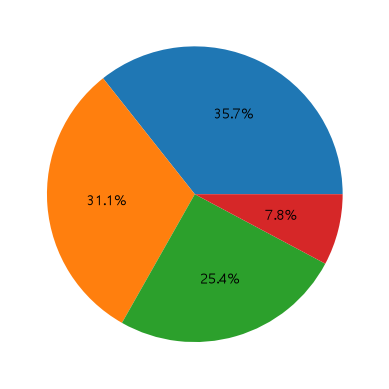

In [14]:
day_count = tips['day'].value_counts()
day_count

# TODO: day_count 를 파이그래프로 그리세요

plt.pie(day_count.values, autopct='%.1f%%')

### 문제 4. 히스토그램 — 결제금액 분포
`total_bill`의 분포를 히스토그램으로 그리세요. (bins=20)

(array([ 1.,  6., 13., 29., 31., 37., 28., 23., 18., 13., 10.,  9.,  5.,
         7.,  3.,  4.,  1.,  2.,  3.,  1.]),
 array([ 3.07 ,  5.457,  7.844, 10.231, 12.618, 15.005, 17.392, 19.779,
        22.166, 24.553, 26.94 , 29.327, 31.714, 34.101, 36.488, 38.875,
        41.262, 43.649, 46.036, 48.423, 50.81 ]),
 <BarContainer object of 20 artists>)

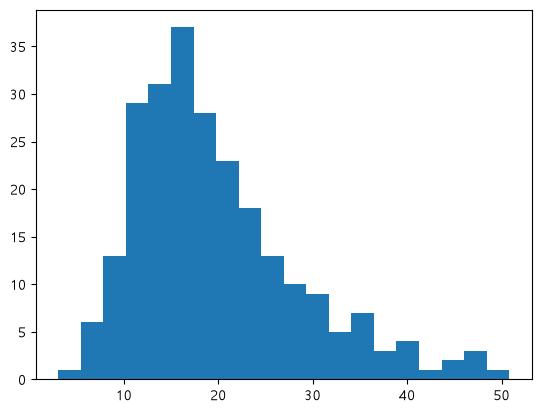

In [15]:
# TODO: tips['total_bill'] 을 bins=20 히스토그램으로 그리세요

plt.hist(tips['total_bill'], bins=20)

### 문제 5. 산점도 — 결제금액 vs 팁
`total_bill`과 `tip`의 관계를 산점도로 그리세요. (alpha=0.5)

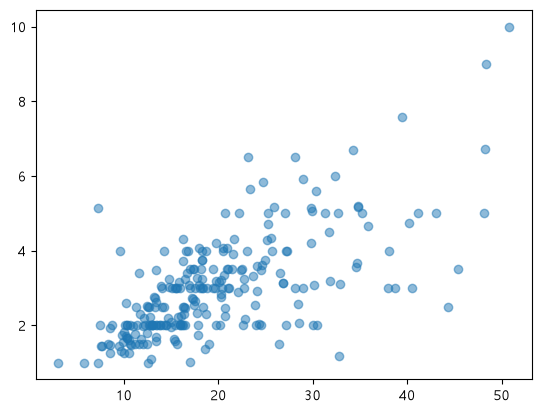

In [17]:
# TODO: total_bill(x) 과 tip(y) 을 산점도로 그리세요

plt.scatter(tips['total_bill'], tips['tip'], alpha=0.5)

## B. 서브플롯

### 문제 6. 2×2 서브플롯
`tips`를 2×2 한 그림에 요약하세요.
1. total_bill 히스토그램  2. tip 히스토그램
3. 요일별 방문 수 막대  4. total_bill vs tip 산점도
- 각 제목 + `suptitle` + `tight_layout`

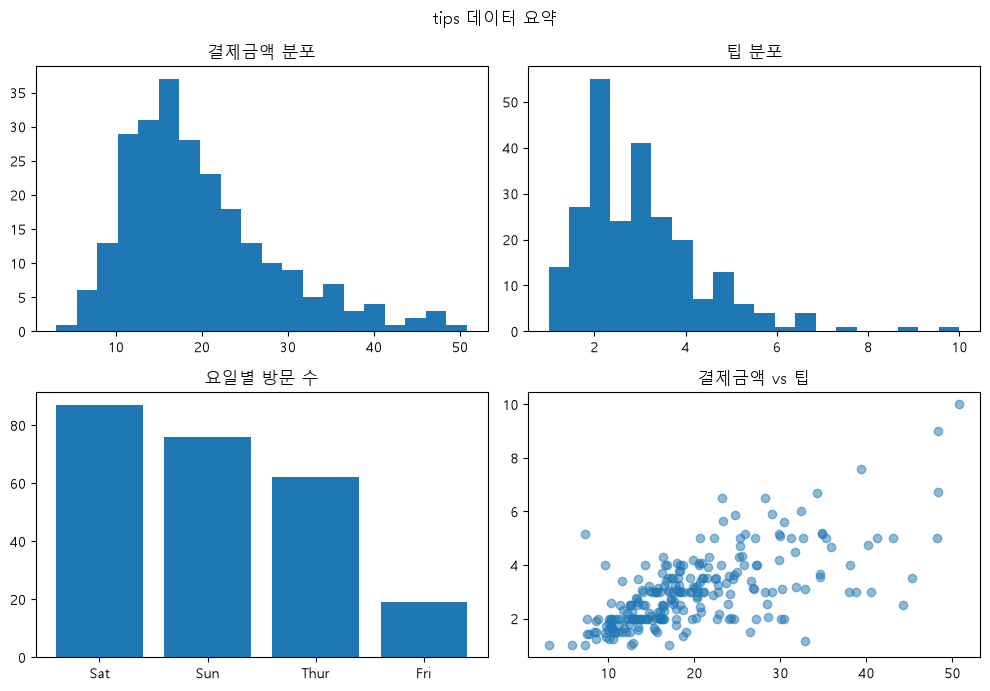

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))

# TODO: axes[행][열] 에 4개의 그래프를 그리고 제목을 넣으세요
axes[0][0].hist(tips['total_bill'], bins=20); axes[0][0].set_title('결제금액 분포')
axes[0][1].hist(tips['tip'], bins=20); axes[0][1].set_title('팁 분포')

day_count = tips['day'].value_counts()
axes[1][0].bar(day_count.index, day_count.values); axes[1][0].set_title('요일별 방문 수')
axes[1][1].scatter(tips['total_bill'], tips['tip'], alpha=0.5); axes[1][1].set_title('결제금액 vs 팁')
fig.suptitle('tips 데이터 요약')
fig.tight_layout()
plt.show()

## C. seaborn

### 문제 7. barplot — 요일·성별 평균 결제금액
요일별 평균 `total_bill`을 **성별(hue)**로 나눠 그리세요. (errorbar=None)

In [ ]:
# TODO: sns.barplot 으로 요일별 평균 결제금액을 성별로 나눠 그리세요


### 문제 8. boxplot — 요일별 결제금액 분포 (흡연 여부)
요일별 `total_bill` 분포를 **흡연 여부(smoker)**로 나눠 상자그림으로 그리세요.

In [ ]:
# TODO: sns.boxplot 으로 요일별 결제금액 분포를 흡연 여부로 나눠 그리세요


### 문제 9. countplot — 요일별 방문 수 (성별)
요일별 방문 수를 **성별(hue)**로 나눠 그리세요.

In [ ]:
# TODO: sns.countplot 으로 요일별 방문 수를 성별로 나눠 그리세요


### 문제 10. heatmap — 요일×성별 평균 팁
요일×성별 평균 `tip`을 피벗테이블로 만든 뒤 히트맵으로 그리세요. (annot=True, fmt='.2f')

> 힌트: `tips.pivot_table(index='day', columns='sex', values='tip', aggfunc='mean')`

In [ ]:
pivot = tips.pivot_table(index='day', columns='sex', values='tip', aggfunc='mean')

# TODO: pivot 을 sns.heatmap 으로 그리세요 (annot, fmt 사용)


### 문제 11. regplot — 결제금액과 팁의 관계
`total_bill`과 `tip`을 산점도+회귀선으로 그리세요. (회귀선 빨강)

In [ ]:
# TODO: sns.regplot 으로 total_bill vs tip 산점도+회귀선을 그리세요


## D. 미션 (실무형)

### 미션 1. 팁이 가장 높은 요일 강조
요일별 평균 팁 막대에서 **가장 높은 요일만 다른 색**으로 강조하세요.

In [ ]:
day_tip = tips.groupby('day')['tip'].mean()

# TODO: 최고 요일만 다른 색으로 강조하는 색 리스트를 만들어 막대그래프를 그리세요


### 미션 2. 흡연 여부별 평균 팁
흡연 여부(smoker)에 따라 평균 팁이 다른지 막대로 비교하세요.

In [ ]:
# TODO: smoker 별 평균 tip 을 barplot 으로 그리세요


## E. 제출 과제
> 평가 대상이라 완성본에도 정답이 없습니다. 스스로 작성해 제출하세요.

### 과제 1. tips 대시보드 (2×2 서브플롯)
하나의 그림에 ① 요일별 평균 결제금액 막대 ② total_bill 히스토그램 ③ 결제금액 vs 팁 산점도(성별 색 구분) ④ 요일별 팁 상자그림을 그리고, 전체 제목·`tight_layout` 적용 후 `plt.savefig('tips_dashboard.png')`로 저장하세요.

In [ ]:
# 여기에 코드를 작성하세요


### 과제 2. "팁을 많이 주는 손님은 누구?" 자유 탐색
성별·흡연여부·시간대(time)·인원수(size) 중 **팁에 영향을 주는 요인**을 2~3개의 그래프로 탐색하고, 각 그래프 아래에 해석을 1줄씩 적으세요. 마지막에 "어떤 손님이 팁을 많이 주는가"를 2~3문장으로 정리하세요.

In [ ]:
# 여기에 코드를 작성하세요
